# Analyse des salaires partagés
### Simulateur de salaire net — Maroc 2026

---

## 1. Contexte et question

Le site *Simulateur de salaire net* permet à chacun de calculer son salaire net à partir de son brut
(CNSS, AMO, frais professionnels, impôt sur le revenu). Les visiteurs qui le souhaitent peuvent ensuite
**ajouter anonymement leur salaire** aux statistiques, avec quelques critères facultatifs :
ville, secteur, expérience et diplôme.

Ce notebook explore ces contributions pour répondre à deux questions :

1. **Quel est le salaire typique des utilisateurs du site ?**
2. **Qu'est-ce qui le fait varier ?** (ville, secteur, expérience, diplôme… et l'impôt lui-même)

Les montants sont **mensuels**, en dirhams (DH).

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

# Couleurs du site
BORDEAUX_FONCE = "#5E1A2E"
BORDEAUX = "#8C2F45"
ROSE = "#E8C9CF"
ENCRE = "#2B1B1F"
GRIS = "#6B5559"

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRIS,
    "axes.labelcolor": ENCRE,
    "axes.titlecolor": BORDEAUX_FONCE,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.grid.axis": "y",
    "grid.color": "#EEE5E2",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})


def fr(nombre, decimales=1):
    # Nombre à la française : 12 345,6
    return f"{nombre:,.{decimales}f}".replace(",", " ").replace(".", ",")


def dh(montant, decimales=0):
    # Montant à la française : 12 345 DH
    return fr(montant, decimales) + " DH"


# Axes graduées en « 12 000 » plutôt que « 12000 »
FORMAT_MILLIERS = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))

pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " ").replace(".", ","))

## 2. Chargement des données

La base du site est un fichier SQLite rangé dans le dossier `instance/`. Le notebook se trouve dans
`analyse/`, d'où le chemin relatif `../instance/simulateur.db`.

La base est ouverte **en lecture seule** : le notebook ne peut rien modifier sur le site.

In [2]:
CHEMIN_BASE = Path("..") / "instance" / "simulateur.db"

if not CHEMIN_BASE.exists():
    raise FileNotFoundError(
        f"Base introuvable : {CHEMIN_BASE.resolve()}\n"
        "Ouvrez ce notebook depuis le dossier analyse/ et lancez au moins une fois "
        "le site ou le script seed_demo.py."
    )

connexion = sqlite3.connect(f"file:{CHEMIN_BASE.as_posix()}?mode=ro", uri=True)
df = pd.read_sql("SELECT * FROM contributions", connexion, parse_dates=["date_ajout"])
connexion.close()

df["est_demo"] = df["est_demo"].astype(bool)

print(f"{len(df)} contributions, {df.shape[1]} colonnes")

301 contributions, 10 colonnes


**Types des colonnes** — les critères facultatifs sont du texte, les salaires des nombres décimaux :

In [3]:
df.dtypes.to_frame("type")

,type
id,int64
date_ajout,datetime64[us]
salaire_brut,float64
salaire_net,float64
personnes_charge,int64
ville,str
secteur,str
experience,str
diplome,str
est_demo,bool


**Les 5 premières lignes :**

In [4]:
df.head()

,id,date_ajout,salaire_brut,salaire_net,personnes_charge,ville,secteur,experience,diplome,est_demo
0,301,2026-10-12,"10 000,00","8 857,69",0,Casablanca,Informatique/Télécom,1-3 ans,Bac+2,False
1,302,2026-09-08,"5 000,00","4 653,50",0,Casablanca,Commerce/Distribution,3-5 ans,Bac+2,True
2,303,2026-06-27,"4 050,00","3 769,34",0,Kénitra,Offshoring/Centres d'appels,3-5 ans,Bac ou moins,True
3,304,2026-07-29,"7 300,00","6 854,82",4,Casablanca,Banque/Assurance,1-3 ans,Bac ou moins,True
4,305,2026-08-01,"4 700,00","4 374,29",1,Casablanca,Offshoring/Centres d'appels,1-3 ans,Bac ou moins,True


## 3. Qualité des données

Avant d'analyser, on vérifie trois choses :

- **les valeurs manquantes** : ville, secteur, expérience et diplôme sont facultatifs sur le site,
  il est donc normal qu'ils soient parfois vides ;
- **les doublons** : deux lignes identiques (hors identifiant et date) ;
- **la part des données de démonstration** (`est_demo = True`), générées pour illustrer le site.

In [5]:
manquantes = df.isna().sum().to_frame("valeurs manquantes")
manquantes["part (%)"] = manquantes["valeurs manquantes"] / len(df) * 100
manquantes

,valeurs manquantes,part (%)
id,0,"0,00"
date_ajout,0,"0,00"
salaire_brut,0,"0,00"
salaire_net,0,"0,00"
personnes_charge,0,"0,00"
ville,18,"5,98"
secteur,16,"5,32"
experience,14,"4,65"
diplome,17,"5,65"
est_demo,0,"0,00"


In [6]:
colonnes_contenu = [c for c in df.columns if c not in ("id", "date_ajout")]
nb_doublons = df.duplicated(subset=colonnes_contenu).sum()
print(f"Lignes identiques à une autre (hors id et date) : {nb_doublons}")

Lignes identiques à une autre (hors id et date) : 0


Les salaires déclarés sont souvent ronds (8 000 DH, 10 000 DH…) : deux personnes différentes peuvent
donc avoir exactement la même ligne. Ces doublons apparents sont **conservés**. Le site limite déjà
les contributions répétées à une par navigateur et par 24 heures.

In [7]:
nb_demo = int(df["est_demo"].sum())
part_demo = nb_demo / len(df) * 100 if len(df) else 0
print(f"Données de démonstration : {nb_demo} sur {len(df)} ({part_demo:.0f} %)")
print(f"Contributions réelles    : {len(df) - nb_demo}")

if nb_demo:
    display(HTML(
        f'<div style="padding:14px 18px;background:{BORDEAUX_FONCE};color:#FAF6F1;'
        f'font-size:1.05em;line-height:1.5">'
        f"<strong>Attention : {part_demo:.0f} % des données sont fictives.</strong><br>"
        "Elles ont été générées par <code style='color:#E8C9CF'>seed_demo.py</code> pour illustrer le site. "
        "Tant que c'est le cas, <strong>toutes les conclusions de ce notebook sont illustratives</strong> "
        "et ne décrivent pas les salaires réels au Maroc.</div>"
    ))

Données de démonstration : 300 sur 301 (100 %)
Contributions réelles    : 1


> **Avertissement** — Tant que l'échantillon est composé (en tout ou partie) de données de démonstration,
> les chiffres de ce notebook montrent **la méthode d'analyse**, pas la réalité du marché du travail.
> Il suffira de relancer le notebook quand de vraies contributions seront arrivées.

## 4. Nettoyage : valeurs aberrantes (méthode IQR)

Une valeur **aberrante** est un salaire très éloigné des autres : erreur de saisie (un zéro de trop)
ou cas réellement exceptionnel.

**La méthode IQR, en clair :**

1. On range les salaires du plus petit au plus grand.
2. Le **1er quartile (Q1)** est le salaire en dessous duquel se trouve un quart des contributions ;
   le **3e quartile (Q3)**, celui en dessous duquel se trouvent les trois quarts.
3. L'**écart interquartile** est `IQR = Q3 − Q1` : c'est la largeur de la moitié centrale.
4. Est jugé aberrant tout salaire situé à plus de **1,5 × IQR** en dessous de Q1 ou au-dessus de Q3.

C'est la même règle que les « moustaches » d'un boxplot (section 6).

Le site refuse déjà les bruts hors de 2 500 à 200 000 DH : les erreurs grossières sont donc écartées
dès la saisie. Les valeurs repérées ici sont surtout de **hauts salaires plausibles**. On les retire
pour les calculs sensibles (moyenne, écart-type), mais on les signale plutôt que de les effacer.

In [8]:
def bornes_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


borne_basse, borne_haute = bornes_iqr(df["salaire_brut"])
df["aberrant"] = ~df["salaire_brut"].between(borne_basse, borne_haute)
df_propre = df[~df["aberrant"]].copy()

print(f"Bornes retenues : de {dh(max(borne_basse, 0))} à {dh(borne_haute)} brut par mois")
print(f"Valeurs aberrantes : {df['aberrant'].sum()} sur {len(df)} "
      f"({fr(df['aberrant'].mean() * 100)} %)")
print(f"Lignes conservées pour la suite : {len(df_propre)}")

Bornes retenues : de 0 DH à 18 200 DH brut par mois
Valeurs aberrantes : 11 sur 301 (3,7 %)
Lignes conservées pour la suite : 290


In [9]:
# Les valeurs écartées, de la plus haute à la plus basse
df.loc[df["aberrant"], ["salaire_brut", "salaire_net", "ville", "secteur", "experience", "diplome"]] \
  .sort_values("salaire_brut", ascending=False)

,salaire_brut,salaire_net,ville,secteur,experience,diplome
79,"27 900,00","20 465,73",Rabat,Informatique/Télécom,Plus de 10 ans,Bac+5
188,"27 400,00","20 107,85",Casablanca,Santé,NaN,Doctorat
222,"26 600,00","19 665,24",Casablanca,Banque/Assurance,5-10 ans,Bac+5
44,"25 150,00","18 672,39",Marrakech,Informatique/Télécom,5-10 ans,Bac+5
168,"24 750,00","18 526,08",Marrakech,Informatique/Télécom,5-10 ans,Bac+5
75,"24 650,00","18 364,51",Autre,Banque/Assurance,Plus de 10 ans,NaN
160,"23 850,00","18 071,90",Autre,Informatique/Télécom,Plus de 10 ans,Doctorat
92,"20 250,00","15 655,15",Casablanca,Banque/Assurance,Plus de 10 ans,Bac+5
45,"20 150,00","15 593,58",Rabat,Informatique/Télécom,5-10 ans,Bac+5
53,"19 750,00","15 347,27",Casablanca,Éducation,Plus de 10 ans,Bac+5


## 5. Statistiques descriptives

Pour chaque série : nombre, moyenne, médiane, quartiles et **écart-type** (la dispersion moyenne
autour de la moyenne). On compare les données complètes et les données nettoyées.

Les quartiles sont calculés par interpolation linéaire, comme sur la page `/statistiques` du site.

In [10]:
def resume(serie):
    return pd.Series({
        "Nombre": serie.count(),
        "Moyenne": serie.mean(),
        "Médiane": serie.median(),
        "1er quartile": serie.quantile(0.25),
        "3e quartile": serie.quantile(0.75),
        "Écart-type": serie.std(),
        "Minimum": serie.min(),
        "Maximum": serie.max(),
    })


descriptives = pd.DataFrame({
    "Brut (toutes les lignes)": resume(df["salaire_brut"]),
    "Brut (nettoyé)": resume(df_propre["salaire_brut"]),
    "Net (nettoyé)": resume(df_propre["salaire_net"]),
})
descriptives

,Brut (toutes les lignes),Brut (nettoyé),Net (nettoyé)
Nombre,"301,00","290,00","290,00"
Moyenne,"8 737,21","8 173,45","7 253,58"
Médiane,"7 600,00","7 450,00","6 876,09"
1er quartile,"5 200,00","5 112,50","4 758,20"
3e quartile,"10 400,00","10 150,00","9 014,88"
Écart-type,"4 703,60","3 725,20","2 935,90"
Minimum,"3 000,00","3 000,00","2 792,10"
Maximum,"27 900,00","17 900,00","14 387,07"


In [11]:
moyenne = df["salaire_brut"].mean()
mediane = df["salaire_brut"].median()
print(f"Moyenne brute  : {dh(moyenne)}")
print(f"Médiane brute  : {dh(mediane)}")
print(f"La moyenne dépasse la médiane de {(moyenne / mediane - 1) * 100:.0f} %")
print(f"Coefficient d'asymétrie : {fr(df['salaire_brut'].skew(), 2)} (0 = distribution symétrique)")

Moyenne brute  : 8 737 DH
Médiane brute  : 7 600 DH
La moyenne dépasse la médiane de 15 %
Coefficient d'asymétrie : 1,49 (0 = distribution symétrique)


**Pourquoi la moyenne est-elle supérieure à la médiane ?**

Les salaires ont une distribution **asymétrique** : beaucoup de personnes gagnent des montants
modestes ou moyens, et quelques-unes gagnent beaucoup plus. Ces hauts salaires « tirent » la moyenne
vers le haut, alors que la médiane, qui est simplement la valeur du milieu, ne bouge presque pas.

Exemple : cinq salaires de 4 000, 5 000, 6 000, 7 000 et 150 000 DH ont une médiane de **6 000 DH**
mais une moyenne de **34 400 DH**, qui ne ressemble à aucun d'entre eux.

C'est pourquoi on utilise **la médiane** pour décrire le salaire « typique ».

## 6. Distribution des salaires

- **À gauche**, l'histogramme en échelle normale : on voit le pic des salaires courants et la longue
  « traîne » vers les hauts salaires.
- **À droite**, la même chose en échelle **logarithmique** : chaque graduation multiplie le salaire
  au lieu de l'augmenter d'un montant fixe. Une distribution « log-normale », typique des salaires,
  y prend une forme de cloche à peu près symétrique.

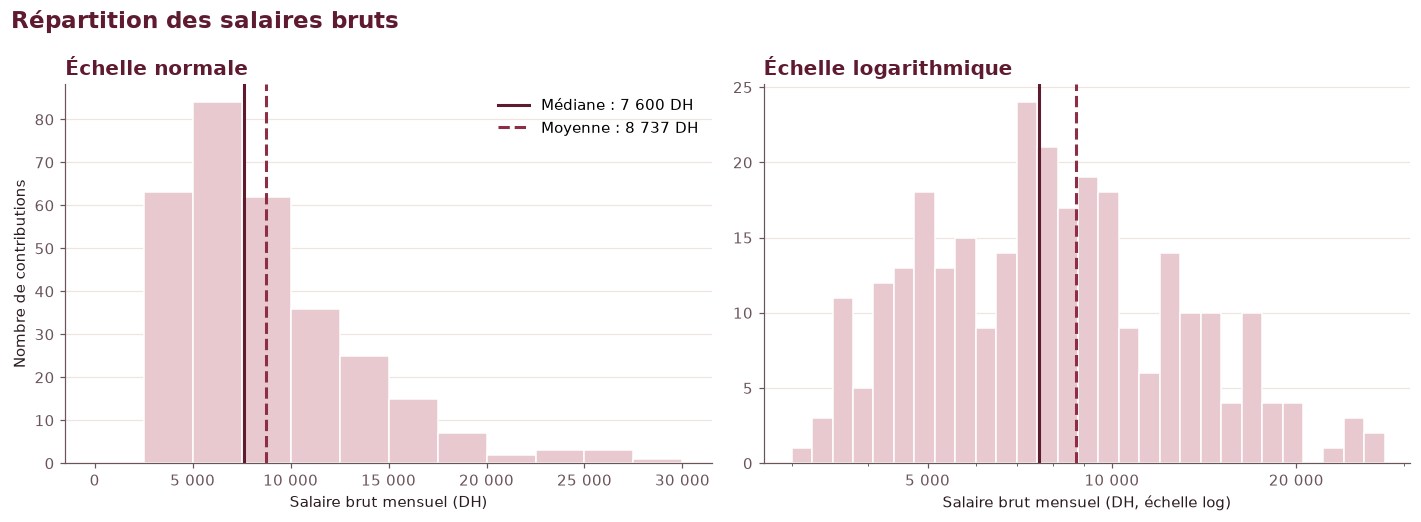

In [12]:
brut = df["salaire_brut"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

ax1.hist(brut, bins=np.arange(0, brut.max() + 2500, 2500), color=ROSE, edgecolor="white")
ax1.axvline(brut.median(), color=BORDEAUX_FONCE, linewidth=2, label=f"Médiane : {dh(brut.median())}")
ax1.axvline(brut.mean(), color=BORDEAUX, linewidth=2, linestyle="--", label=f"Moyenne : {dh(brut.mean())}")
ax1.set_title("Échelle normale")
ax1.set_xlabel("Salaire brut mensuel (DH)")
ax1.set_ylabel("Nombre de contributions")
ax1.xaxis.set_major_formatter(FORMAT_MILLIERS)
ax1.legend()

bins_log = np.logspace(np.log10(brut.min()), np.log10(brut.max()), 30)
ax2.hist(brut, bins=bins_log, color=ROSE, edgecolor="white")
ax2.axvline(brut.median(), color=BORDEAUX_FONCE, linewidth=2)
ax2.axvline(brut.mean(), color=BORDEAUX, linewidth=2, linestyle="--")
ax2.set_xscale("log")
ax2.set_xlim(brut.min() * 0.9, brut.max() * 1.1)
ax2.set_xticks([t for t in (2500, 5000, 10000, 20000, 50000, 100000, 200000)
                if brut.min() * 0.9 <= t <= brut.max() * 1.1])
ax2.xaxis.set_major_formatter(FORMAT_MILLIERS)
ax2.xaxis.set_minor_formatter(mticker.NullFormatter())
ax2.set_title("Échelle logarithmique")
ax2.set_xlabel("Salaire brut mensuel (DH, échelle log)")

fig.suptitle("Répartition des salaires bruts", x=0.01, ha="left", fontsize=15,
             fontweight="bold", color=BORDEAUX_FONCE)
fig.tight_layout()
plt.show()

Le **boxplot** résume la distribution en une ligne : la boîte va du 1er au 3e quartile, le trait
central est la médiane, les moustaches s'arrêtent à 1,5 × IQR et les points isolés sont les valeurs
aberrantes de la section 4.

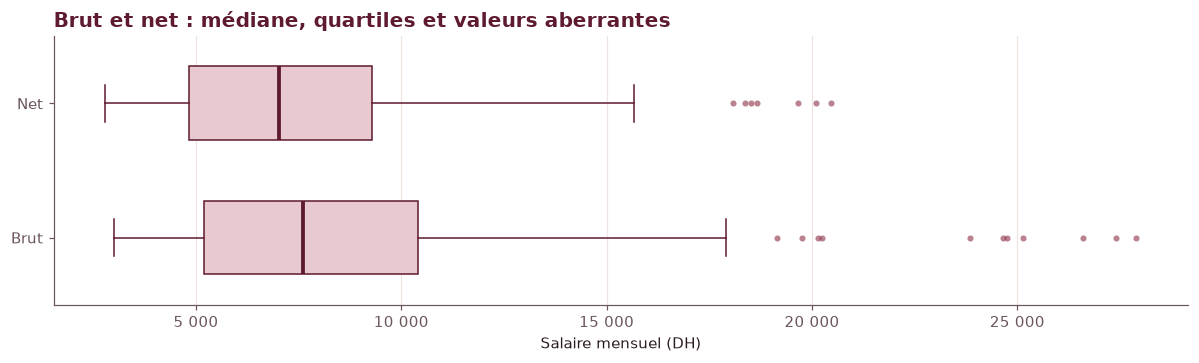

In [13]:
fig, ax = plt.subplots(figsize=(11, 3.4))
style_boite = dict(
    widths=0.55, patch_artist=True,
    boxprops=dict(facecolor=ROSE, edgecolor=BORDEAUX_FONCE),
    medianprops=dict(color=BORDEAUX_FONCE, linewidth=2.5),
    whiskerprops=dict(color=BORDEAUX_FONCE),
    capprops=dict(color=BORDEAUX_FONCE),
    flierprops=dict(marker="o", markersize=4, markerfacecolor=BORDEAUX,
                    markeredgecolor="none", alpha=0.6),
)
salaires = [df["salaire_brut"], df["salaire_net"]]
try:
    ax.boxplot(salaires, orientation="horizontal", **style_boite)
except TypeError:  # matplotlib antérieur à 3.10
    ax.boxplot(salaires, vert=False, **style_boite)
ax.set_yticks([1, 2], ["Brut", "Net"])
ax.set_xlabel("Salaire mensuel (DH)")
ax.xaxis.set_major_formatter(FORMAT_MILLIERS)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Brut et net : médiane, quartiles et valeurs aberrantes")
fig.tight_layout()
plt.show()

## 7. Qu'est-ce qui fait varier le salaire ?

On compare la **médiane du salaire brut** selon la ville, le secteur, l'expérience et le diplôme,
sur les données nettoyées.

Comme sur le site, seuls les groupes d'**au moins 5 contributions** sont affichés : une médiane
calculée sur 2 ou 3 personnes ne veut pas dire grand-chose, et pourrait permettre de les reconnaître.
La ligne pointillée rappelle la médiane générale.

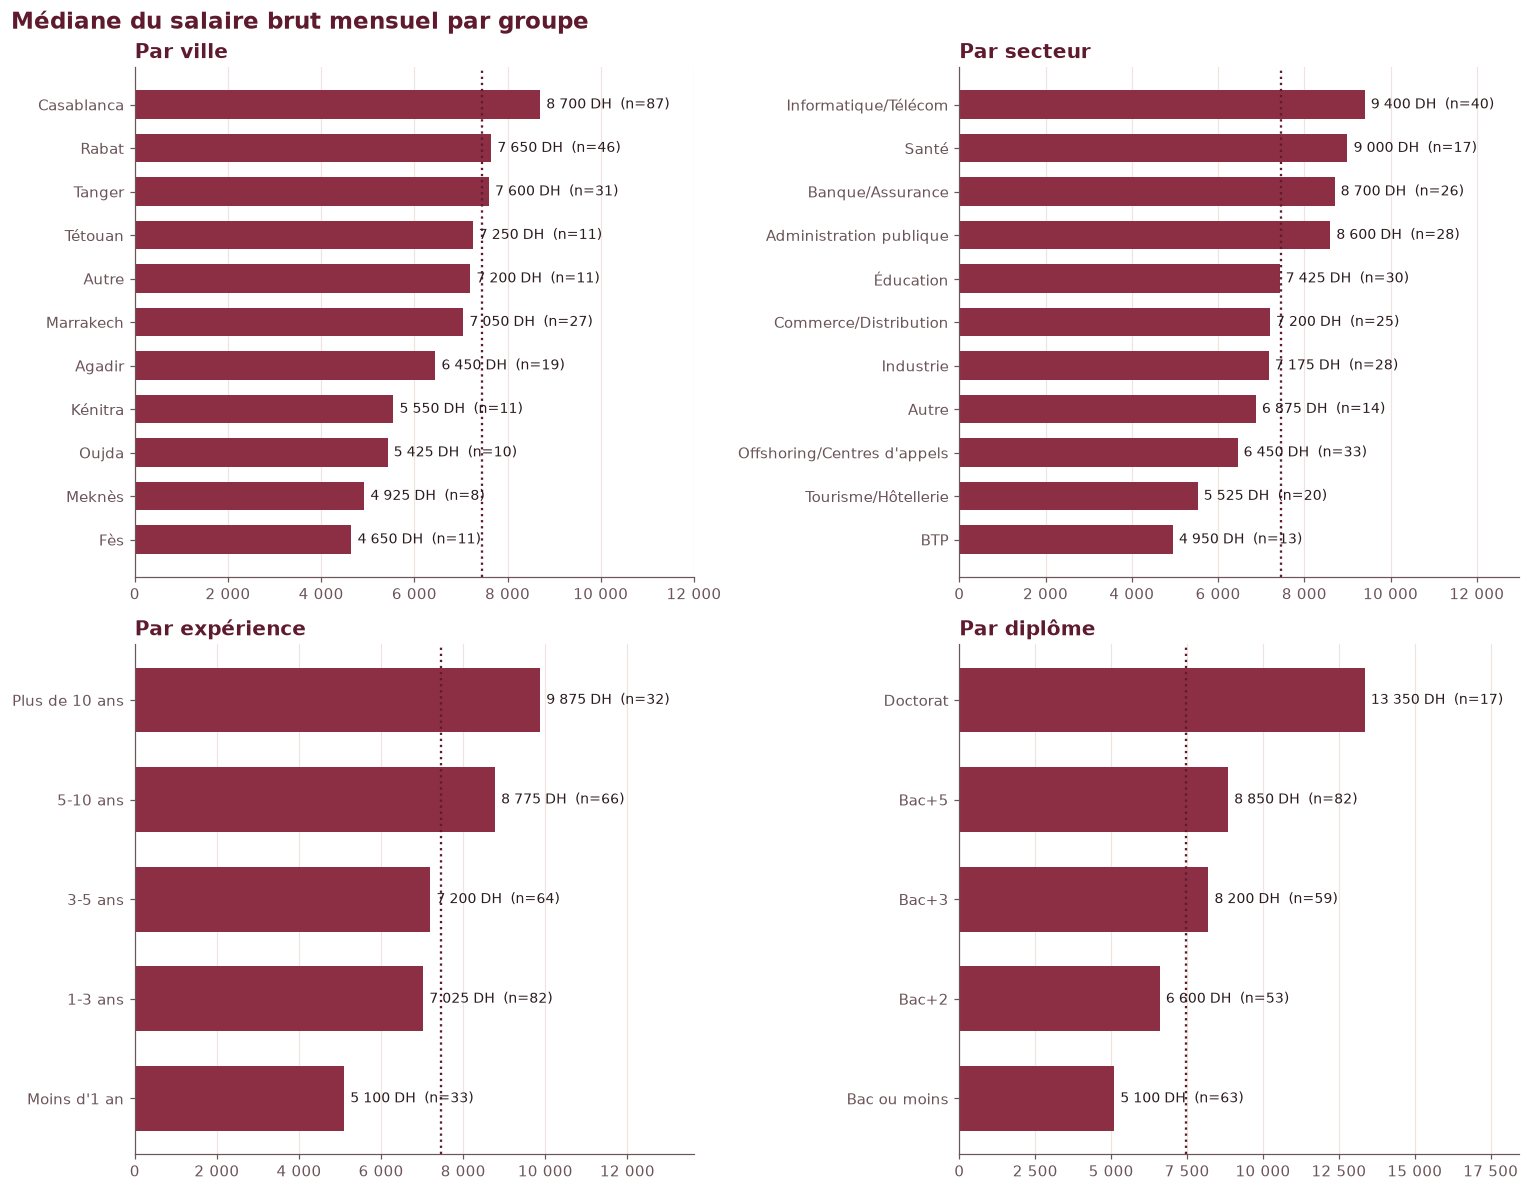

In [14]:
MIN_GROUPE = 5
CRITERES = {"ville": "Ville", "secteur": "Secteur", "experience": "Expérience", "diplome": "Diplôme"}


def medianes_par(colonne, donnees=df_propre):
    groupes = donnees.groupby(colonne)["salaire_brut"].agg(mediane="median", nombre="count")
    affiches = groupes[groupes["nombre"] >= MIN_GROUPE].sort_values("mediane")
    masques = groupes[groupes["nombre"] < MIN_GROUPE]
    return affiches, masques


mediane_generale = df_propre["salaire_brut"].median()
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (colonne, titre) in zip(axes.flat, CRITERES.items()):
    affiches, masques = medianes_par(colonne)
    barres = ax.barh(affiches.index, affiches["mediane"], color=BORDEAUX, height=0.65)
    ax.bar_label(barres, labels=[f"{dh(m)}  (n={n})" for m, n in zip(affiches["mediane"], affiches["nombre"])],
                 padding=4, fontsize=9, color=ENCRE)
    ax.axvline(mediane_generale, color=BORDEAUX_FONCE, linestyle=":", linewidth=1.5)
    ax.set_title(f"Par {titre.lower()}")
    ax.xaxis.set_major_formatter(FORMAT_MILLIERS)
    ax.set_xlim(0, affiches["mediane"].max() * 1.38 if len(affiches) else 1)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    if len(masques):
        ax.text(0, -0.08, f"Masqués (moins de {MIN_GROUPE}) : {', '.join(masques.index)}",
                transform=ax.transAxes, fontsize=8.5, color=GRIS, style="italic")

fig.suptitle("Médiane du salaire brut mensuel par groupe", x=0.01, ha="left",
             fontsize=15, fontweight="bold", color=BORDEAUX_FONCE)
fig.tight_layout()
plt.show()

Pour comparer l'influence des quatre critères, on mesure pour chacun l'**écart entre le groupe le
mieux payé et le moins bien payé** (rapport des médianes). Plus ce rapport est élevé, plus le critère
« fait varier » le salaire.

In [15]:
ecarts = []
for colonne, titre in CRITERES.items():
    affiches, _ = medianes_par(colonne)
    if len(affiches) >= 2:
        ecarts.append({
            "critère": titre,
            "groupe le moins payé": affiches.index[0],
            "groupe le mieux payé": affiches.index[-1],
            "rapport des médianes": affiches["mediane"].iloc[-1] / affiches["mediane"].iloc[0],
        })

ecarts = pd.DataFrame(ecarts).sort_values("rapport des médianes", ascending=False).reset_index(drop=True)
ecarts

,critère,groupe le moins payé,groupe le mieux payé,rapport des médianes
0,Diplôme,Bac ou moins,Doctorat,"2,62"
1,Expérience,Moins d'1 an,Plus de 10 ans,"1,94"
2,Secteur,BTP,Informatique/Télécom,"1,90"
3,Ville,Fès,Casablanca,"1,87"


## 8. Taux de prélèvement effectif

Indépendamment des contributions, on peut étudier **le barème lui-même**. On importe directement
`calcul.py`, le module de calcul du site : ce sont donc exactement les mêmes formules (CNSS, AMO,
frais professionnels, IR 2026).

Pour chaque brut de 3 000 à 50 000 DH (célibataire sans personne à charge), on trace la part du brut
prélevée :

- **cotisations** (CNSS + IPE + AMO) ;
- **impôt sur le revenu** (IR).

In [16]:
# calcul.py et config.py sont dans le dossier parent (racine du projet)
sys.path.insert(0, str(Path("..").resolve()))
import config  # noqa: E402
from calcul import calcul_salaire  # noqa: E402

bruts = np.arange(3000, 50001, 100)
lignes = []
for b in bruts:
    r = calcul_salaire(float(b), 0)
    lignes.append({
        "brut": b,
        "net": r["net"],
        "cotisations (%)": r["total_cotisations"] / b * 100,
        "IR (%)": r["ir"] / b * 100,
    })
bareme = pd.DataFrame(lignes)
bareme["total (%)"] = bareme["cotisations (%)"] + bareme["IR (%)"]

# Taux marginal : part prélevée sur les 100 DH bruts supplémentaires
bareme["taux marginal (%)"] = (1 - bareme["net"].diff() / bareme["brut"].diff()) * 100

bareme.set_index("brut").loc[[3000, 4000, 6500, 6900, 7000, 12000, 25000, 50000],
                             ["net", "cotisations (%)", "IR (%)", "total (%)"]]

,net,cotisations (%),IR (%),total (%)
brut,,,,
3000,"2 792,10","6,93","0,00","6,93"
4000,"3 722,80","6,93","0,00","6,93"
6500,"6 011,49","6,57","0,94","7,52"
6900,"6 377,04","6,32","1,26","7,58"
7000,"6 402,81","6,26","2,27","8,53"
12000,"10 362,54","4,59","9,05","13,65"
25000,"18 580,02","3,38","22,30","25,68"
50000,"33 974,07","2,82","29,23","32,05"


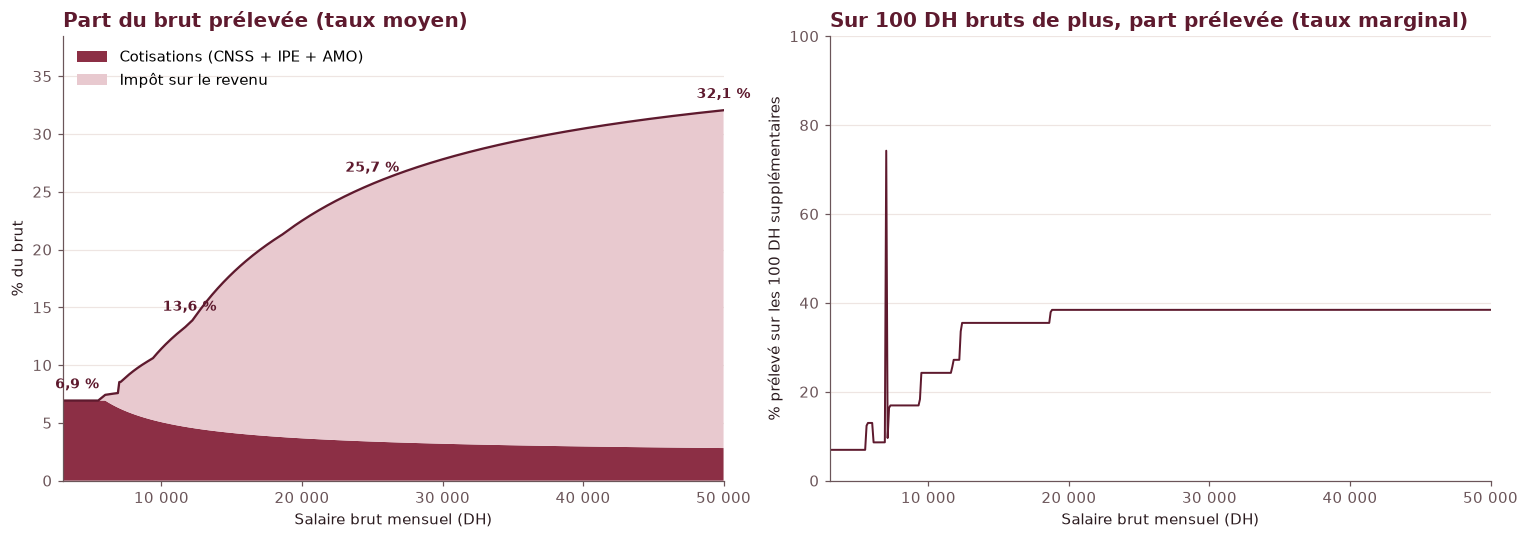

Taux moyen : 6,9 % à 3 000 DH, 32,1 % à 50 000 DH
Pic du taux marginal : 74 % en passant à 7 000 DH brut


In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.stackplot(bareme["brut"], bareme["cotisations (%)"], bareme["IR (%)"],
              colors=[BORDEAUX, ROSE], labels=["Cotisations (CNSS + IPE + AMO)", "Impôt sur le revenu"])
ax1.plot(bareme["brut"], bareme["total (%)"], color=BORDEAUX_FONCE, linewidth=1.5)
for b in (4000, 12000, 25000, 50000):
    t = bareme.loc[bareme["brut"] == b, "total (%)"].iloc[0]
    ax1.annotate(f"{fr(t)} %", (b, t), xytext=(0, 8), textcoords="offset points",
                 ha="center", fontsize=9, color=BORDEAUX_FONCE, fontweight="bold")
ax1.set_title("Part du brut prélevée (taux moyen)")
ax1.set_xlabel("Salaire brut mensuel (DH)")
ax1.set_ylabel("% du brut")
ax1.xaxis.set_major_formatter(FORMAT_MILLIERS)
ax1.set_xlim(3000, 50000)
ax1.set_ylim(0, bareme["total (%)"].max() * 1.2)
ax1.legend(loc="upper left")

ax2.plot(bareme["brut"], bareme["taux marginal (%)"], color=BORDEAUX_FONCE, linewidth=1.3)
ax2.set_title("Sur 100 DH bruts de plus, part prélevée (taux marginal)")
ax2.set_xlabel("Salaire brut mensuel (DH)")
ax2.set_ylabel("% prélevé sur les 100 DH supplémentaires")
ax2.xaxis.set_major_formatter(FORMAT_MILLIERS)
ax2.set_xlim(3000, 50000)
ax2.set_ylim(0, 100)

fig.tight_layout()
plt.show()

pic = bareme.loc[bareme["taux marginal (%)"].idxmax()]
print(f"Taux moyen : {fr(bareme['total (%)'].iloc[0])} % à 3 000 DH, "
      f"{fr(bareme['total (%)'].iloc[-1])} % à 50 000 DH")
print(f"Pic du taux marginal : {pic['taux marginal (%)']:.0f} % en passant à {dh(pic['brut'])} brut")

**Commentaire : un impôt progressif**

- **Cotisations** : leur part *baisse* au-delà de 6 000 DH, parce que la CNSS est plafonnée.
  Seule l'AMO (2,26 %) continue de s'appliquer sur tout le salaire.
- **Impôt sur le revenu** : nul pour les petits salaires (revenu net imposable sous 40 000 DH/an),
  il augmente ensuite par tranches de 10 % à 37 %. C'est lui qui rend l'ensemble **progressif** :
  plus le salaire est élevé, plus la *part* prélevée est grande.
- Le taux affiché est un **taux moyen**. Même dans la tranche à 37 %, on ne perd jamais 37 % de tout
  son salaire : seule la partie au-dessus de chaque seuil est taxée à ce taux.
- Le graphique de droite montre un **effet de seuil**. Les frais professionnels sont calculés sur le
  **brut imposable** (brut moins cotisations salariales) : 35 % tant que celui-ci ne dépasse pas
  78 000 DH par an, 25 % au-delà. Au moment où l'on franchit ce seuil, l'abattement diminue d'un coup,
  le revenu imposable fait un saut et l'IR augmente brutalement.

### Où se situe exactement le seuil, et combien coûte-t-il ?

On cherche, avec `calcul.py`, le dernier salaire brut pour lequel les frais professionnels restent à
35 %, puis on compare le net juste avant et juste après.

In [18]:
# Recherche par dichotomie du dernier brut (au centime) encore au taux de 35 %
bas, haut = 3000.0, 50000.0
while haut - bas > 1e-6:
    milieu = (bas + haut) / 2
    if calcul_salaire(milieu, 0)["taux_frais_pro"] == config.FRAIS_PRO_TAUX_BAS:
        bas = milieu
    else:
        haut = milieu
seuil = np.floor(bas * 100) / 100
net_seuil = calcul_salaire(seuil, 0)["net"]

chute = calcul_salaire(seuil + 0.01, 0)["net"] - net_seuil
gain_100 = calcul_salaire(seuil + 100, 0)["net"] - net_seuil
part_perdue_100 = (1 - gain_100 / 100) * 100

brut_retour = seuil + 0.01
while calcul_salaire(brut_retour, 0)["net"] < net_seuil:
    brut_retour = round(brut_retour + 0.01, 2)

effet_seuil = pd.DataFrame(
    [(d, calcul_salaire(seuil + d, 0)["net"] - net_seuil) for d in (0.01, 10, 50, 100, 200, 500)],
    columns=["hausse du brut (DH)", "variation du net (DH)"],
)
effet_seuil["part de la hausse perdue (%)"] = (1 - effet_seuil["variation du net (DH)"]
                                               / effet_seuil["hausse du brut (DH)"]) * 100

display(Markdown("\n".join([
    f"- **Seuil** : **{dh(seuil, 2)} brut par mois** (brut imposable de "
    f"{dh(calcul_salaire(seuil, 0)['brut_imposable'] * 12)} par an).",
    f"- **Un centime de plus** et le net **baisse de {dh(-chute, 2)}** : les frais professionnels "
    f"passent de 35 % à 25 %.",
    f"- **Une augmentation de 100 DH** à partir du seuil ne rapporte que {dh(gain_100, 2)} net : "
    f"**{fr(part_perdue_100)} % de l'augmentation est perdue**.",
    f"- Il faut atteindre **{dh(brut_retour, 2)} brut** (soit {dh(brut_retour - seuil, 2)} de plus) "
    f"pour retrouver le net du seuil ({dh(net_seuil, 2)}).",
])))
effet_seuil.set_index("hausse du brut (DH)")

- **Seuil** : **6 936,97 DH brut par mois** (brut imposable de 78 000 DH par an).
- **Un centime de plus** et le net **baisse de 64,99 DH** : les frais professionnels passent de 35 % à 25 %.
- **Une augmentation de 100 DH** à partir du seuil ne rapporte que 25,41 DH net : **74,6 % de l'augmentation est perdue**.
- Il faut atteindre **7 008,87 DH brut** (soit 71,90 DH de plus) pour retrouver le net du seuil (6 410,83 DH).

,variation du net (DH),part de la hausse perdue (%)
hausse du brut (DH),,
"0,01","-64,99","650 000,00"
"10,00","-55,96","659,60"
"50,00","-19,80","139,60"
"100,00","25,41","74,59"
"200,00","113,66","43,17"
"500,00","362,89","27,42"


Concrètement, une **petite augmentation** qui fait franchir le seuil **fait baisser le salaire net**.
Au-delà d'environ 70 DH bruts de plus, on redevient gagnant, mais une bonne partie de l'augmentation
part encore en impôt. C'est un effet connu des barèmes « en marche d'escalier » : il porte ici sur
l'abattement pour frais professionnels, pas sur le barème de l'IR lui-même, qui est progressif
sans à-coup grâce à la somme à déduire.

## 9. Conclusions et limites

### Cinq conclusions

Les chiffres ci-dessous sont **calculés à partir des données présentes dans la base** au moment de
l'exécution : ils se mettront à jour quand de nouvelles contributions arriveront.

In [19]:
q1, q3 = df_propre["salaire_brut"].quantile([0.25, 0.75])
mediane_net = df_propre["salaire_net"].median()
taux_a_la_mediane = bareme.iloc[(bareme["brut"] - mediane_generale).abs().argmin()]["total (%)"]

points = [
    f"**Salaire typique** : après nettoyage, la médiane est de **{dh(mediane_generale)} brut**, soit environ "
    f"**{dh(mediane_net)} net** par mois. La moitié des contributions se situe entre "
    f"{dh(q1)} et {dh(q3)} brut.",

    f"**Distribution asymétrique** : sur toutes les contributions, la moyenne ({dh(moyenne)}) "
    f"dépasse la médiane ({dh(mediane)}) de {(moyenne / mediane - 1) * 100:.0f} %, "
    "à cause d'une minorité de hauts salaires. "
    "La médiane est l'indicateur à retenir.",
]

if len(ecarts):
    premier = ecarts.iloc[0]
    points.append(
        f"**Critère le plus discriminant** : {premier['critère'].lower()}. La médiane va de "
        f"*{premier['groupe le moins payé']}* à *{premier['groupe le mieux payé']}*, "
        f"soit un rapport de **{fr(premier['rapport des médianes'])}**."
    )
    autres = ", ".join(f"{c.lower()} ({fr(r)})" for c, r in
                       zip(ecarts["critère"].iloc[1:], ecarts["rapport des médianes"].iloc[1:]))
    points.append(f"**Autres critères**, par écart décroissant : {autres}.")
else:
    points += ["**Critères** : pas encore assez de contributions par groupe pour comparer.", ""]

points.append(
    f"**Fiscalité progressive, avec un effet de seuil** : la part prélevée passe de "
    f"{bareme['total (%)'].iloc[0]:.0f} % à 3 000 DH à {bareme['total (%)'].iloc[-1]:.0f} % à "
    f"50 000 DH (environ {taux_a_la_mediane:.0f} % au salaire médian). À {dh(seuil, 2)} brut, "
    f"les frais professionnels passent de 35 % à 25 % : le net baisse de {dh(-chute, 2)} au "
    f"franchissement, et une augmentation de 100 DH y perd {fr(part_perdue_100)} %."
)

display(Markdown("\n".join(f"{i}. {p}" for i, p in enumerate(filter(None, points), 1))))

1. **Salaire typique** : après nettoyage, la médiane est de **7 450 DH brut**, soit environ **6 876 DH net** par mois. La moitié des contributions se situe entre 5 112 DH et 10 150 DH brut.
2. **Distribution asymétrique** : sur toutes les contributions, la moyenne (8 737 DH) dépasse la médiane (7 600 DH) de 15 %, à cause d'une minorité de hauts salaires. La médiane est l'indicateur à retenir.
3. **Critère le plus discriminant** : diplôme. La médiane va de *Bac ou moins* à *Doctorat*, soit un rapport de **2,6**.
4. **Autres critères**, par écart décroissant : expérience (1,9), secteur (1,9), ville (1,9).
5. **Fiscalité progressive, avec un effet de seuil** : la part prélevée passe de 7 % à 3 000 DH à 32 % à 50 000 DH (environ 9 % au salaire médian). À 6 936,97 DH brut, les frais professionnels passent de 35 % à 25 % : le net baisse de 64,99 DH au franchissement, et une augmentation de 100 DH y perd 74,6 %.

### Limites

- **Données de démonstration** : tant que la base contient des contributions fictives (voir section 3),
  ces conclusions sont **illustratives**. Elles montrent la méthode, pas la réalité.
- **Biais de sélection** : seuls les visiteurs du site contribuent, et seulement s'ils le veulent.
  Ce sont plutôt des personnes connectées, curieuses de leur fiche de paie, peut-être plus diplômées
  et plus urbaines que la moyenne. L'échantillon **n'est pas représentatif** des salariés marocains.
- **Déclarations non vérifiées** : chacun saisit son brut librement. Les contrôles du site
  (de 2 500 à 200 000 DH, une contribution par navigateur et par 24 h) limitent les abus sans les
  empêcher.
- **Petits groupes** : en dessous de 5 contributions, un groupe est masqué. Au-dessus, une médiane
  sur 10 ou 20 personnes reste fragile.
- **Corrélations, pas causes** : un écart entre secteurs peut venir du diplôme ou de la ville des
  personnes qui y travaillent. Pour séparer ces effets, il faudrait un modèle multivarié
  (régression), avec beaucoup plus de données.